In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Cargar y preprocesar el conjunto de datos MNIST
mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Normalizar los píxeles al rango [0, 1] y añadir canal de color (28, 28, 1)
X_train = X_train.reshape((-1, 28, 28, 1)).astype('float32') / 255.0
X_test = X_test.reshape((-1, 28, 28, 1)).astype('float32') / 255.0

# 2. Definir la arquitectura de la CNN
model = models.Sequential([
    # Primera capa convolucional
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    
    # Segunda capa convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Tercera capa convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),
    
    # Capas densas para clasificación
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5), # Regularización para evitar sobreajuste
    layers.Dense(10, activation='softmax')
])

# 3. Compilar el modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Entrenar la red
print("Iniciando entrenamiento...")
model.fit(X_train, y_train, epochs=5, batch_size=64, validation_data=(X_test, y_test))

# 5. Evaluar precisión en el conjunto de prueba
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrecisión en datos de prueba: {test_acc * 100:.2f}%")

# 6. Exportar el modelo
model_filename = 'cnn_mnist_model.keras'
model.save(model_filename)
print(f"Modelo guardado exitosamente como: '{model_filename}'")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 66s 6us/step


c:\Users\jtjua\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Iniciando entrenamiento...
Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 18s 16ms/step - accuracy: 0.9038 - loss: 0.3171 - val_accuracy: 0.9792 - val_loss: 0.0622
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 17s 18ms/step - accuracy: 0.9710 - loss: 0.1013 - val_accuracy: 0.9876 - val_loss: 0.0395
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.9793 - loss: 0.0735 - val_accuracy: 0.9901 - val_loss: 0.0345
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.9833 - loss: 0.0596 - val_accuracy: 0.9871 - val_loss: 0.0391
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9863 - loss: 0.0483 - val_accuracy: 0.9912 - val_loss: 0.0284

Precisión en datos de prueba: 99.12%
Modelo guardado exitosamente como: 'cnn_mnist_model.keras'


In [2]:
import tensorflow as tf

# Cargar el modelo desde el archivo generado
loaded_model = tf.keras.models.load_model('cnn_mnist_model.keras')

# predictions = loaded_model.predict(nueva_imagen)

In [3]:
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. Cargar y preprocesar el conjunto de datos CIFAR-10
cifar10 = tf.keras.datasets.cifar10
(X_train, y_train), (X_test, y_test) = cifar10.load_data()

# Normalizar los píxeles al rango [0, 1]
# CIFAR-10 ya tiene 3 canales de color (32, 32, 3)
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Nombres de las 10 clases de CIFAR-10 (para interpretación)
class_names = ['avión', 'automóvil', 'pájaro', 'gato', 'ciervo', 
               'perro', 'rana', 'caballo', 'barco', 'camión']

# 2. Definir la arquitectura de la CNN
model = models.Sequential([
    # Bloque Convolucional 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.2),

    # Bloque Convolucional 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.3),

    # Bloque Convolucional 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.4),

    # Capas de Clasificación
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

# 3. Compilar el modelo
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 4. Entrenar la red
print("Iniciando entrenamiento en CIFAR-10...")
history = model.fit(
    X_train, y_train, 
    epochs=20, 
    batch_size=64, 
    validation_data=(X_test, y_test)
)

# 5. Evaluar precisión en el conjunto de prueba
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrecisión en datos de prueba: {test_acc * 100:.2f}%")

# 6. Exportar el modelo
model_filename = 'cnn_cifar10_model.keras'
model.save(model_filename)
print(f"Modelo guardado exitosamente como: '{model_filename}'")

 25034752/170498071 ━━━━━━━━━━━━━━━━━━━━ 29:27 12us/step

KeyboardInterrupt: 

In [ ]:
import numpy as np
import tensorflow as tf

# Cargar el modelo exportado
loaded_model = tf.keras.models.load_model('cnn_cifar10_model.keras')

# Predecir sobre la primera imagen de prueba
img = X_test[0:1] # Mantener dimensión de lote (1, 32, 32, 3)
prediccion = loaded_model.predict(img)
clase_predicha = class_names[np.argmax(prediccion)]

print(f"Clase predicha: {clase_predicha}")

In [4]:
pip install ultralytics opencv-python matplotlib

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 1.4/1.4 MB 7.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/44.0 MB ? eta -:--:--
   ---------------------------------------- 0.5/44.0 MB 3.4 MB/s eta 0:00:13
    --------------------------------------- 0.8/44.0 MB 2.1 MB/s eta 0:00:21
    --------------------------------------- 1.0/44.0 MB 1.8 MB/s eta 0:00:25
   - -------------------------------------- 1.3/44.0 MB 1.6 MB/s eta 0:00:26
   - -------------------------------------- 1.6/44.0 MB 1.4 MB/s eta 0:00:31
   - -------------------------------------- 1.6/44.0 MB 1.4 MB/s eta 0:00:31
   - -------------------------------------- 1.8/44.0 MB 1.2 MB/s eta 0:00:37
   - -------------------------------------- 1.8/44.0 MB 1.2 MB/s eta 0:00:37
   - -------------------------------------- 1.8/44.0 MB 1.2 MB/s eta 0:00:37
   - -------------------------------------- 2.1/44.0 MB 959.5 kB/s eta 0:00:44
   - --------


image 1/1 c:\Users\jtjua\arturo\AIEafit\walter.jpeg: 640x480 1 cat, 222.6ms
Speed: 11.6ms preprocess, 222.6ms inference, 27.7ms postprocess per image at shape (1, 3, 640, 480)


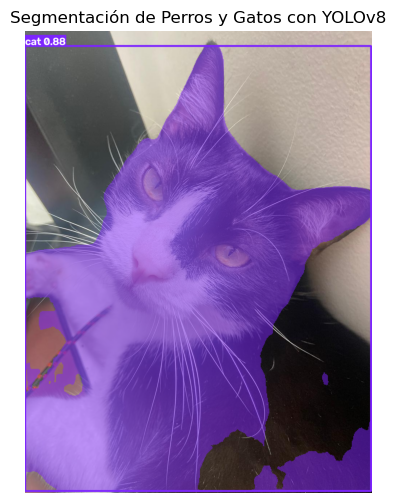


Se detectaron 1 mascotas.
- Mascota 1: Gato | Vértices de la máscara: 955


In [7]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

# 1. Cargar el modelo YOLOv8 especializado en segmentación (versión nano)
model = YOLO('yolov8n-seg.pt')

# ID de las clases en COCO: 15 -> cat, 16 -> dog
PET_CLASSES = [15, 16]

# 2. Cargar tu imagen (reemplaza 'mascotas.jpg' por la ruta de tu archivo)
image_path = 'walter.jpeg'
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# 3. Realizar la inferencia filtrando solo las clases de interés
results = model(image_path, classes=PET_CLASSES, conf=0.5)[0]

# 4. Dibujar las máscaras y cajas detectadas
# .plot() genera automáticamente la visualización con las máscaras sobrepuestas
annotated_frame = results.plot()
annotated_frame_rgb = cv2.cvtColor(annotated_frame, cv2.COLOR_BGR2RGB)

# 5. Mostrar el resultado
plt.figure(figsize=(10, 6))
plt.imshow(annotated_frame_rgb)
plt.axis('off')
plt.title('Segmentación de Perros y Gatos con YOLOv8')
plt.show()

# 6. Opcional: Obtener los polígonos de las máscaras individualmente
if results.masks is not None:
    masks_polygons = results.masks.xy  # Lista de coordenadas (x, y) de cada polígono
    boxes = results.boxes.xyxy         # Cajas delimitadoras
    clases = results.boxes.cls         # ID de la clase detectada (15 o 16)

    print(f"\nSe detectaron {len(masks_polygons)} mascotas.")
    for i, (cls, poly) in enumerate(zip(clases, masks_polygons)):
        nombre_clase = "Gato" if int(cls) == 15 else "Perro"
        print(f"- Mascota {i+1}: {nombre_clase} | Vértices de la máscara: {len(poly)}")

In [11]:
pip install mediapipe opencv-python

  Using cached mediapipe-1.0.1-py3-none-win_amd64.whl.metadata (10 kB)
  Using cached sounddevice-0.5.6-py3-none-win_amd64.whl.metadata (1.4 kB)
  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached mediapipe-1.0.1-py3-none-win_amd64.whl (20.1 MB)
Using cached sounddevice-0.5.6-py3-none-win_amd64.whl (1.0 MB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl (53.8 MB)

   ---------------------------------------- 0/3 [opencv-contrib-python]

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'c:\\Users\\jtjua\\anaconda3\\Lib\\site-packages\\cv2\\cv2.pyd'
Consider using the `--user` option or check the permissions.



In [9]:
wget -O hand_landmarker.task https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task

SyntaxError: invalid syntax (429355862.py, line 1)

In [1]:
import os
import urllib.request
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# 1. Descarga automática del modelo si no existe en la carpeta actual
model_filename = "hand_landmarker.task"
model_url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"

if not os.path.exists(model_filename):
    print("Descargando modelo 'hand_landmarker.task'...")
    urllib.request.urlretrieve(model_url, model_filename)
    print("Descarga completada.")

# 2. Configurar el detector usando la API de Tasks
base_options = python.BaseOptions(model_asset_path=model_filename)
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_tracking_confidence=0.5
)
detector = vision.HandLandmarker.create_from_options(options)

# 3. Definición manual de conexiones de los 21 puntos clave (Reemplaza mp.solutions.hands)
HAND_CONNECTIONS = [
    # Pulgar
    (0, 1), (1, 2), (2, 3), (3, 4),
    # Índice
    (0, 5), (5, 6), (6, 7), (7, 8),
    # Medio
    (9, 10), (10, 11), (11, 12),
    # Anular
    (13, 14), (14, 15), (15, 16),
    # Meñique
    (0, 17), (17, 18), (18, 19), (19, 20),
    # Palma (conexiones transversales entre nudillos base)
    (5, 9), (9, 13), (13, 17)
]

# 4. Inicializar la cámara web
cap = cv2.VideoCapture(0)
print("Iniciando tracker. Presiona 'q' en la ventana de la cámara para salir.")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        print("No se pudo acceder a la cámara.")
        break

    frame = cv2.flip(frame, 1)
    h, w, _ = frame.shape

    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

    # Inferencia de la CNN
    detection_result = detector.detect(mp_image)

    # 5. Dibujar los puntos y líneas del esqueleto
    if detection_result.hand_landmarks:
        for hand_landmarks in detection_result.hand_landmarks:
            points = [(int(lm.x * w), int(lm.y * h)) for lm in hand_landmarks]

            # Dibujar huesos (líneas verdes)
            for start_idx, end_idx in HAND_CONNECTIONS:
                cv2.line(frame, points[start_idx], points[end_idx], (0, 255, 0), 2)

            # Dibujar articulaciones (círculos rojos)
            for cx, cy in points:
                cv2.circle(frame, (cx, cy), 5, (0, 0, 255), -1)

    cv2.imshow('Hand Tracking - MediaPipe Tasks', frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

Iniciando tracker. Presiona 'q' en la ventana de la cámara para salir.


Finger Detect


In [1]:
import os
import urllib.request
import cv2
import mediapipe as mp
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

# 1. Asegurar la presencia del modelo
model_filename = "hand_landmarker.task"
model_url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/1/hand_landmarker.task"

if not os.path.exists(model_filename):
    print("Descargando modelo...")
    urllib.request.urlretrieve(model_url, model_filename)

# 2. Configurar el detector
base_options = python.BaseOptions(model_asset_path=model_filename)
options = vision.HandLandmarkerOptions(
    base_options=base_options,
    num_hands=1,                         # Limitar a 1 mano para simplicidad
    min_hand_detection_confidence=0.5,
    min_tracking_confidence=0.5
)
detector = vision.HandLandmarker.create_from_options(options)

# Conexiones de los huesos para dibujo
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),
    (0, 5), (5, 6), (6, 7), (7, 8),
    (9, 10), (10, 11), (11, 12),
    (13, 14), (14, 15), (15, 16),
    (0, 17), (17, 18), (18, 19), (19, 20),
    (5, 9), (9, 13), (13, 17)
]

# 3. Función para contar los dedos levantados
def contar_dedos(landmarks):
    # Puntos de las puntas (Tips) de los 4 dedos largos
    tips_ids = [8, 12, 16, 20]
    dedos_arriba = []

    # --- Pulgar ---
    # Comparar coordenada X de la punta (4) con la articulación previa (3)
    # (Asumiendo palma hacia la cámara)
    if landmarks[4].x < landmarks[3].x:
        dedos_arriba.append(1)
    else:
        dedos_arriba.append(0)

    # --- Los 4 dedos restantes ---
    # Comparar coordenada Y de la punta con su articulación PIP (dos nodos abajo)
    for tip_id in tips_ids:
        pip_id = tip_id - 2
        if landmarks[tip_id].y < landmarks[pip_id].y:  # Menor Y significa más arriba
            dedos_arriba.append(1)
        else:
            dedos_arriba.append(0)

    # La suma total indica la cantidad de dedos extendidos
    total_dedos = sum(dedos_arriba)
    return total_dedos, dedos_arriba

# 4. Bucle principal de vídeo
cap = cv2.VideoCapture(0)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.flip(frame, 1) # Espejo
    h, w, _ = frame.shape

    rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb_frame)

    detection_result = detector.detect(mp_image)

    if detection_result.hand_landmarks:
        landmarks = detection_result.hand_landmarks[0]
        
        # Calcular dedos levantados
        total_dedos, estado_dedos = contar_dedos(landmarks)

        # Convertir a píxeles para dibujar
        points = [(int(lm.x * w), int(lm.y * h)) for lm in landmarks]

        # Dibujar esqueleto
        for start_idx, end_idx in HAND_CONNECTIONS:
            cv2.line(frame, points[start_idx], points[end_idx], (0, 255, 0), 2)

        for cx, cy in points:
            cv2.circle(frame, (cx, cy), 5, (0, 0, 255), -1)

        # Mostrar contador grande en pantalla
        cv2.rectangle(frame, (20, 20), (220, 100), (0, 0, 0), cv2.FILLED)
        cv2.putText(
            frame, 
            f"Dedos: {total_dedos}", 
            (30, 80), 
            cv2.FONT_HERSHEY_SIMPLEX, 
            1.8, 
            (0, 255, 255), 
            3
        )

    cv2.imshow('Contador de Dedos con MediaPipe', frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()